### Import Libraries

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

### Load Dataset

In [5]:
df = pd.read_excel("sample_-_superstore.xls")
print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


### Check Required Columns

In [6]:
print(df[['Product Name', 'Sales', 'Profit', 'Quantity']].head())

                                        Product Name    Sales   Profit  \
0  Message Book, Wirebound, Four 5 1/2" X 4" Form...   16.448   5.5512   
1         GBC Standard Plastic Binding Systems Combs    3.540  -5.4870   
2                                          Avery 508   11.784   4.2717   
3                      SAFCO Boltless Steel Shelving  272.736 -64.7748   
4  Avery Hi-Liter EverBold Pen Style Fluorescent ...   19.536   4.8840   

   Quantity  
0         2  
1         2  
2         3  
3         3  
4         3  


### Rank Products by Revenue

In [7]:
revenue_ranking = df.groupby('Product Name')['Sales'].sum().reset_index()

revenue_ranking = revenue_ranking.sort_values(
    by='Sales', ascending=False
)

revenue_ranking['Revenue Rank'] = revenue_ranking['Sales'].rank(
    method='dense', ascending=False
).astype(int)

print(revenue_ranking.head(10))

                                          Product Name      Sales  \
404              Canon imageCLASS 2200 Advanced Copier  61599.824   
649  Fellowes PB500 Electric Punch Plastic Comb Bin...  27453.384   
444  Cisco TelePresence System EX90 Videoconferenci...  22638.480   
785       HON 5400 Series Task Chairs for Big and Tall  21870.576   
685         GBC DocuBind TL300 Electric Binding System  19823.479   
687   GBC Ibimaster 500 Manual ProClick Binding System  19024.500   
804               Hewlett Packard LaserJet 3310 Copier  18839.686   
786  HP Designjet T520 Inkjet Large Format Printer ...  18374.895   
682          GBC DocuBind P400 Electric Binding System  17965.068   
812        High Speed Automatic Electric Letter Opener  17030.312   

     Revenue Rank  
404             1  
649             2  
444             3  
785             4  
685             5  
687             6  
804             7  
786             8  
682             9  
812            10  


### Rank Products by Profit

In [8]:
profit_ranking = df.groupby('Product Name')['Profit'].sum().reset_index()

profit_ranking = profit_ranking.sort_values(
    by='Profit', ascending=False
)

profit_ranking['Profit Rank'] = profit_ranking['Profit'].rank(
    method='dense', ascending=False
).astype(int)

print(profit_ranking.head(10))

                                           Product Name      Profit  \
404               Canon imageCLASS 2200 Advanced Copier  25199.9280   
649   Fellowes PB500 Electric Punch Plastic Comb Bin...   7753.0390   
804                Hewlett Packard LaserJet 3310 Copier   6983.8836   
400                  Canon PC1060 Personal Laser Copier   4570.9347   
786   HP Designjet T520 Inkjet Large Format Printer ...   4094.9766   
165                   Ativa V4110MDD Micro-Cut Shredder   3772.9461   
19     3D Systems Cube Printer, 2nd Generation, Magenta   3717.9714   
1275  Plantronics Savi W720 Multi-Device Wireless He...   3696.2820   
894                Ibico EPK-21 Electric Binding System   3345.2823   
1839                  Zebra ZM400 Thermal Label Printer   3343.5360   

      Profit Rank  
404             1  
649             2  
804             3  
400             4  
786             5  
165             6  
19              7  
1275            8  
894             9  
1839           10 

### Rank Products by Quantity

In [9]:
quantity_ranking = df.groupby('Product Name')['Quantity'].sum().reset_index()

quantity_ranking = quantity_ranking.sort_values(
    by='Quantity', ascending=False
)

quantity_ranking['Quantity Rank'] = quantity_ranking['Quantity'].rank(
    method='dense', ascending=False
).astype(int)

print(quantity_ranking.head(10))

                                           Product Name  Quantity  \
1498                                            Staples       234   
1492                                    Staple envelope       170   
536                                   Easy-staple paper       150   
1499                            Staples in misc. colors        86   
1175                            Nu-Dell Executive Frame        84   
941                          KI Adjustable-Height Table        79   
683           GBC DocuBind P50 Personal Binding Machine        72   
1510                            Storex Dura Pro Binders        71   
259                             Avery Non-Stick Binders        71   
698   GBC Premium Transparent Covers with Diagonal L...        67   

      Quantity Rank  
1498              1  
1492              2  
536               3  
1499              4  
1175              5  
941               6  
683               7  
1510              8  
259               8  
698               9 

## Visualize Top 10 Products

### A. Top 10 Products by Revenue

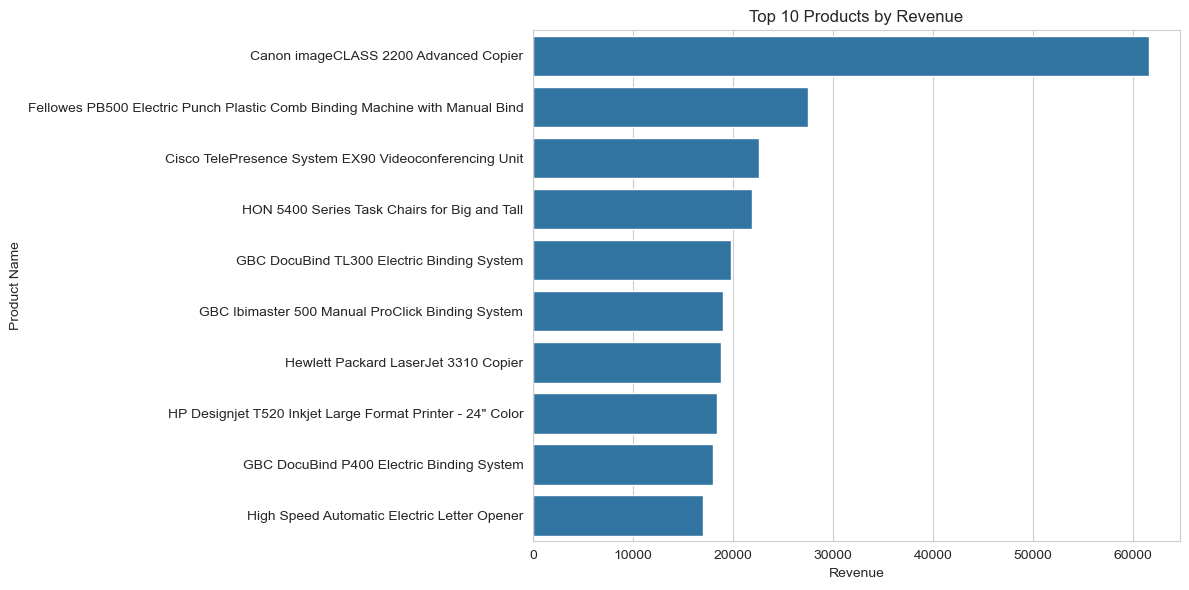

In [10]:
top_revenue = revenue_ranking.head(10)

plt.figure(figsize=(12,6))
sns.barplot(data=top_revenue, x='Sales', y='Product Name')

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product Name')
plt.tight_layout()

plt.savefig('top_10_revenue.png', dpi=300, bbox_inches='tight')
plt.show()

### B. Top 10 Products by Profit

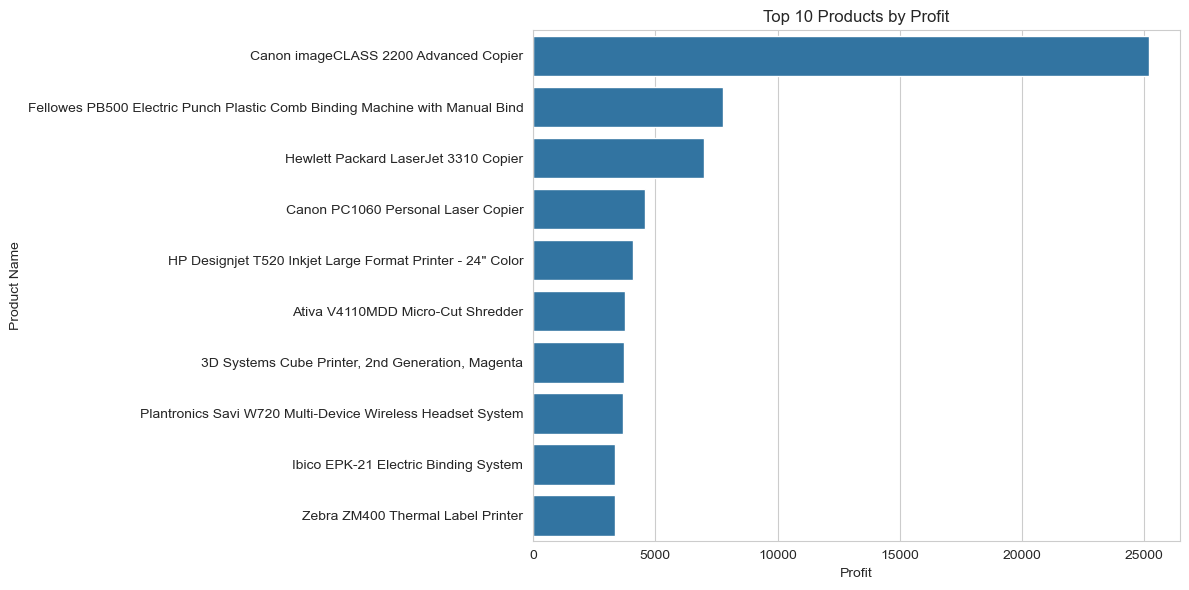

In [11]:
top_profit = profit_ranking.head(10)

plt.figure(figsize=(12,6))
sns.barplot(data=top_profit, x='Profit', y='Product Name')

plt.title('Top 10 Products by Profit')
plt.xlabel('Profit')
plt.ylabel('Product Name')
plt.tight_layout()

plt.savefig('top_10_profit.png', dpi=300, bbox_inches='tight')
plt.show()

### C. Top 10 Products by Quantity

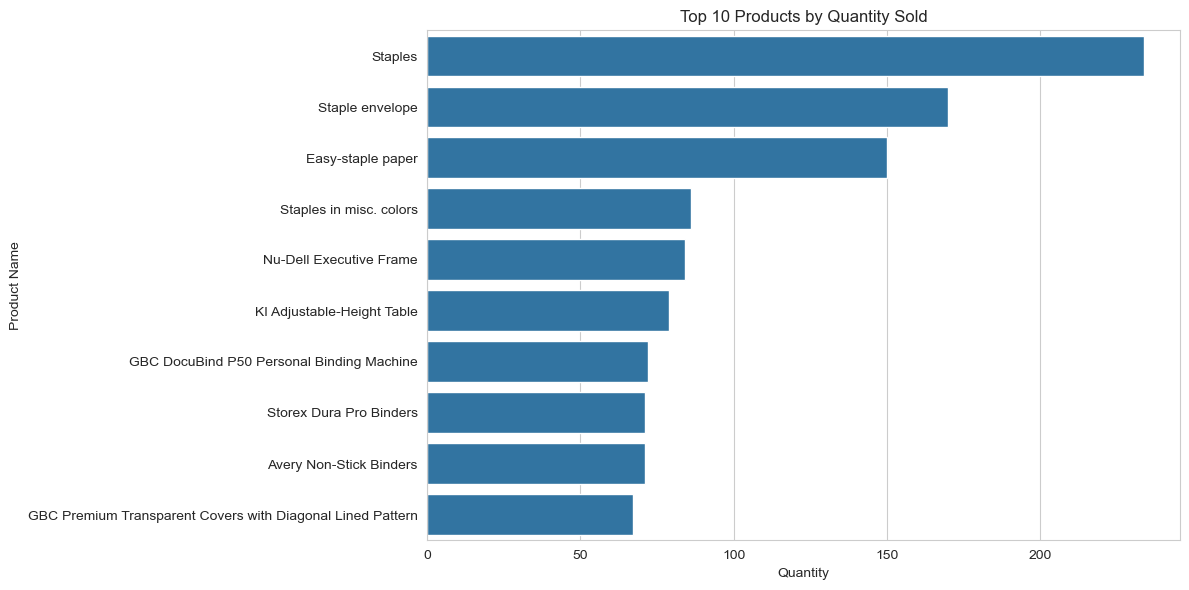

In [12]:
top_quantity = quantity_ranking.head(10)

plt.figure(figsize=(12,6))
sns.barplot(data=top_quantity, x='Quantity', y='Product Name')

plt.title('Top 10 Products by Quantity Sold')
plt.xlabel('Quantity')
plt.ylabel('Product Name')
plt.tight_layout()

plt.savefig('top_10_quantity.png', dpi=300, bbox_inches='tight')
plt.show()

### Export Ranking Results

In [13]:
with pd.ExcelWriter('Day_7_Product_Ranking.xlsx') as writer:
    revenue_ranking.to_excel(writer, sheet_name='Revenue Ranking', index=False)
    profit_ranking.to_excel(writer, sheet_name='Profit Ranking', index=False)
    quantity_ranking.to_excel(writer, sheet_name='Quantity Ranking', index=False)

In [15]:
## Business Insights
#1. Identified the top-performing products based on revenue.
#2. Ranked products according to total profit.
#3. Identified products with the highest sales quantity.
#4. Compared product performance across three different metrics.
#5. Identified products that generate high revenue and high profit.
#6. These rankings help businesses improve inventory planning and sales strategies.

## Conclusion

#Product ranking based on revenue, profit, and quantity
#helps businesses identify their best-performing products.
#It supports better sales planning, inventory management,
#and business decision-making.